# 06 — Intervalles de confiance, impact sur les agrégats, score final et soumission

Le modèle final est le **mélange 0,20 · LightGBM + 0,80 · TCN** (notebook 05). Ce notebook répond à quatre questions :

| Partie | Question |
|---|---|
| A | À quel point se fier à chaque valeur reconstruite ? (intervalles conformes) |
| B | Le modèle fausse-t-il les bilans d'énergie ? (biais, courbe agrégée) |
| C | Quel est le score honnête ? (holdout, utilisé ici pour la première et unique fois) |
| D | La soumission au challenge |

**Ordre des décisions** : tout ce qui se choisit (variante d'intervalles, correction éventuelle du biais) est décidé en A et B sur la **calibration**, **dev** et **real**. Le **holdout** n'est chargé qu'en partie C, après toutes les décisions, et rien n'est réglé ensuite.

In [1]:
# torch et LightGBM embarquent chacun leur propre bibliothèque OpenMP : un seul thread OpenMP
# évite le conflit (erreur de segmentation) quand les deux tournent dans le même processus.
import os

os.environ["OMP_NUM_THREADS"] = "1"

In [2]:
# Imports et configuration
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import torch
from matplotlib.ticker import PercentFormatter

from enedis_imputation.data import PROCESSED_DIR, load_test, load_train
from enedis_imputation.deep import TCN, calibration_set, make_blend_method, make_network_method
from enedis_imputation.gbm import (
    TRAIN_CACHE,
    GBMConfig,
    build_training_set,
    make_method,
    train_cached,
)
from enedis_imputation.holes import LENGTH_LABELS, hole_runs
from enedis_imputation.knn import anchored_knn
from enedis_imputation.methods import knn_median, linear_interpolation
from enedis_imputation.submission import (
    check_submission,
    read_sample,
    to_submission,
    write_submission,
)
from enedis_imputation.tracking import log_evaluation, setup_mlflow
from enedis_imputation.uncertainty import (
    ALPHAS,
    bias_table,
    coverage_table,
    difficulty,
    fit_conformal,
    fit_difficulty,
    intervals,
    predict_components,
)
from enedis_imputation.validation import Split, evaluate, load_split, motif_masks, paired_difference
from enedis_imputation.viz import PALETTE as P
from enedis_imputation.viz import method_color, plot_imputation, save_fig, set_conclusion, set_style

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
setup_mlflow("06_score_final")
dev, real = load_split("dev"), load_split("real")  # le holdout n'est chargé qu'en partie C
motifs = motif_masks().to_numpy()

gbm_cfg = GBMConfig("residual", 63)
ts = build_training_set(dev.reservoir, motifs)
_, booster, _ = train_cached(ts, gbm_cfg, TRAIN_CACHE.with_suffix(".json").read_text())
tcn = TCN(repeats=1)
tcn.load_state_dict(torch.load(PROCESSED_DIR / "deep_tcn.pt", map_location="cpu"))
W = 0.20  # poids du LightGBM, choisi sur la calibration au notebook 05 (revérifié ci-dessous)

## A. Intervalles de confiance par prédiction conforme

**Principe.** Sur des courbes jamais vues, on mesure l'erreur du mélange en chaque point manquant ; le quantile conforme de ces erreurs, au niveau 90 %, donne une demi-largeur d'intervalle qui contient la vraie valeur 9 fois sur 10.

- **Calibration** : les 1 000 courbes du réservoir du notebook 05, jamais cibles d'entraînement, remplies avec un réservoir qui les exclut (jamais dev).
- **Trois variantes** : (1) un quantile **par classe** de longueur de trou ; (2) **normalisée** : l'erreur est divisée par une difficulté σ̂ prédite pour chaque point, si bien que l'intervalle s'élargit là où le modèle a du mal ; (3) normalisée **et** par classe.
- **Modèle de difficulté** : un petit LightGBM entraîné sur les données d'entraînement du réservoir (étape 5), qui prédit |y − KNN ancré| hors pli à partir du désaccord des voisines, de la longueur du trou, des distances aux bords, du niveau de la courbe… Il n'a jamais vu la calibration.
- **Règle de choix**, fixée avant de voir les résultats : à chaque niveau visé, une variante doit couvrir au moins *visé − 1 point* globalement et *visé − 3 points* dans chaque classe, sur dev **et** real ; parmi celles-là, la plus étroite (largeur moyenne sur dev).

In [3]:
diff_model = fit_difficulty(ts)
del ts
calib = calibration_set(dev.reservoir, motifs)
sets = {
    "calibration": (calib.X_holed, calib.pool, calib.y),
    "dev": (dev.X_holed, dev.reservoir, dev.y),
    "real": (real.X_holed, real.reservoir, real.y),
}
comp, truth, sigma = {}, {}, {}
for name, (X, R, y) in sets.items():
    comp[name] = predict_components(X, R, booster, gbm_cfg, tcn, W)
    truth[name] = y.to_numpy()[comp[name].t, comp[name].c]
    sigma[name] = difficulty(diff_model, comp[name].feats)

# Revérification du poids du mélange sur la calibration (même grille qu'au notebook 05)
cal = comp["calibration"]
ok = ~np.isnan(truth["calibration"])
grid = np.round(np.arange(0, 1.0001, 0.05), 2)
mae_w = [
    np.abs(np.clip(w * cal.lightgbm + (1 - w) * cal.network, 0, None) - truth["calibration"])[
        ok
    ].mean()
    for w in grid
]
print(f"w optimal sur la calibration : {grid[int(np.argmin(mae_w))]:.2f} (attendu {W:.2f})")
err_cal = np.abs(cal.blend - truth["calibration"])
rho = pd.Series(sigma["calibration"]).corr(pd.Series(err_cal), method="spearman")
print(f"Corrélation de rang difficulté prédite / erreur réelle (calibration) : {rho:.2f}")

w optimal sur la calibration : 0.20 (attendu 0.20)
Corrélation de rang difficulté prédite / erreur réelle (calibration) : 0.67


In [4]:
kinds = ["classe", "normalisé", "normalisé par classe"]
conformal = {
    k: fit_conformal(err_cal[ok], cal.classes[ok], k, sigma=sigma["calibration"][ok]) for k in kinds
}

cov = {}
for split in ["dev", "real"]:
    cp = comp[split]
    for alpha in ALPHAS:
        for k in kinds:
            low, high = intervals(
                conformal[k], cp.blend, cp.classes, sigma=sigma[split], alpha=alpha
            )
            cov[(split, f"{1 - alpha:.0%}", k)] = coverage_table(
                truth[split], low, high, cp.classes
            )
cov_table = pd.concat({key: t["couverture"] for key, t in cov.items()}, axis=1).T.rename_axis(
    ["jeu", "niveau", "variante"]
)
width_table = pd.concat({key: t["largeur (W)"] for key, t in cov.items()}, axis=1).T
display(cov_table.round(3))
display(width_table.rename_axis(["jeu", "niveau", "variante"]).round(1))


def valid(k: str) -> bool:
    """La variante respecte-t-elle la règle de couverture, à tous les niveaux, sur dev et real ?"""
    for split in ["dev", "real"]:
        for alpha in ALPHAS:
            t = cov[(split, f"{1 - alpha:.0%}", k)]["couverture"]
            if t["toutes"] < 1 - alpha - 0.01 or (t[LENGTH_LABELS] < 1 - alpha - 0.03).any():
                return False
    return True


eligible = [k for k in kinds if valid(k)]
chosen = min(eligible or kinds, key=lambda k: cov[("dev", "90%", k)].loc["toutes", "largeur (W)"])
print("Variantes qui respectent la règle :", eligible)
print("Variante retenue :", chosen)

classe                               1     2   3-6  7-48   >48  toutes
jeu  niveau variante                                                  
dev  80%    classe               0.790 0.787 0.790 0.803 0.784   0.794
            normalisé            0.787 0.794 0.807 0.813 0.824   0.803
            normalisé par classe 0.807 0.800 0.800 0.802 0.807   0.803
     90%    classe               0.892 0.888 0.891 0.896 0.892   0.893
            normalisé            0.890 0.896 0.900 0.908 0.917   0.901
            normalisé par classe 0.904 0.898 0.900 0.899 0.906   0.901
real 80%    classe               0.793 0.789 0.790 0.802 0.814   0.798
            normalisé            0.782 0.794 0.793 0.816 0.826   0.801
            normalisé par classe 0.802 0.800 0.784 0.803 0.813   0.802
     90%    classe               0.891 0.893 0.889 0.898 0.903   0.895
            normalisé            0.886 0.897 0.895 0.912 0.917   0.901
            normalisé par classe 0.902 0.899 0.895 0.902 0.905   0.901

classe                                 1       2     3-6    7-48     >48  \
jeu  niveau variante                                                       
dev  80%    classe               117.800 131.700 149.500 209.300 219.600   
            normalisé            140.700 163.500 184.200 254.900 296.100   
            normalisé par classe 151.200 166.900 179.100 244.300 280.500   
     90%    classe               215.700 243.800 261.500 353.700 375.000   
            normalisé            217.500 251.900 282.300 382.800 446.000   
            normalisé par classe 234.500 253.800 283.100 364.500 420.300   
real 80%    classe               118.300 132.300 149.100 210.400 215.600   
            normalisé            139.100 163.000 179.900 258.900 259.900   
            normalisé par classe 149.500 166.400 174.800 247.900 246.300   
     90%    classe               216.100 244.700 259.400 357.000 365.300   
            normalisé            215.400 251.900 276.500 390.300 390.200   
            normalisé par classe 232.300 253.800 277.300 371.400 367.800   

classe                            toutes  
jeu  niveau variante                      
dev  80%    classe               166.000  
            normalisé            204.500  
            normalisé par classe 202.800  
     90%    classe               290.100  
            normalisé            310.500  
            normalisé par classe 306.900  
real 80%    classe               166.300  
            normalisé            201.900  
            normalisé par classe 200.200  
     90%    classe               290.600  
            normalisé            307.300  
            normalisé par classe 303.700

Variantes qui respectent la règle : ['classe', 'normalisé', 'normalisé par classe']
Variante retenue : classe


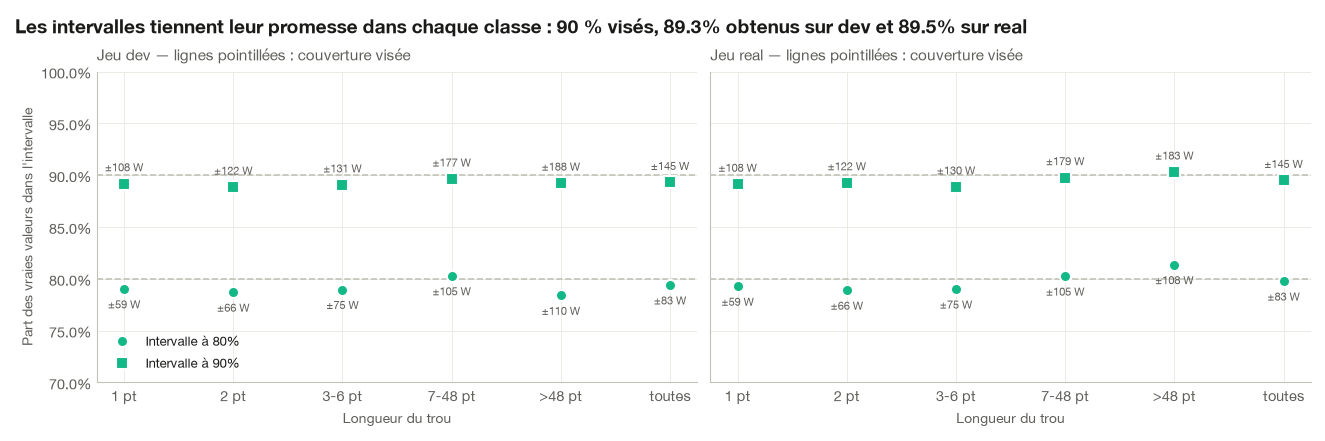

In [5]:
# Figure : couverture visée contre couverture obtenue, par classe (variante retenue)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
x = np.arange(len(LENGTH_LABELS) + 1)
for ax, split in zip(axes, ["dev", "real"], strict=True):
    for alpha, marker in zip(ALPHAS, ["o", "s"], strict=True):
        level = f"{1 - alpha:.0%}"
        t = cov[(split, level, chosen)]
        ax.axhline(1 - alpha, color=P["axis"], lw=1.2, ls="--")
        ax.plot(
            x,
            t["couverture"].to_numpy(),
            marker=marker,
            ms=8,
            lw=0,
            color=method_color("Mélange"),
            mec="white",
            mew=1.5,
            label=f"Intervalle à {level}",
        )
        for xi, (v, w) in enumerate(zip(t["couverture"], t["largeur (W)"], strict=True)):
            ax.annotate(
                f"±{w / 2:.0f} W",
                (xi, v),
                xytext=(0, -14 if alpha == 0.2 else 9),
                textcoords="offset points",
                ha="center",
                fontsize=8,
                color=P["ink_secondary"],
            )
    ax.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS] + ["toutes"])
    ax.set_ylim(0.7, 1.0)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(f"Jeu {split} — lignes pointillées : couverture visée")
    ax.set_xlabel("Longueur du trou")
axes[0].set_ylabel("Part des vraies valeurs dans l'intervalle")
axes[0].legend(loc="lower left")
c90 = {s: cov[(s, "90%", chosen)].loc["toutes", "couverture"] for s in ["dev", "real"]}
set_conclusion(
    fig,
    f"Les intervalles tiennent leur promesse dans chaque classe : 90 % visés, "
    f"{c90['dev']:.1%} obtenus sur dev et {c90['real']:.1%} sur real",
)
save_fig(fig, "u1_couverture");

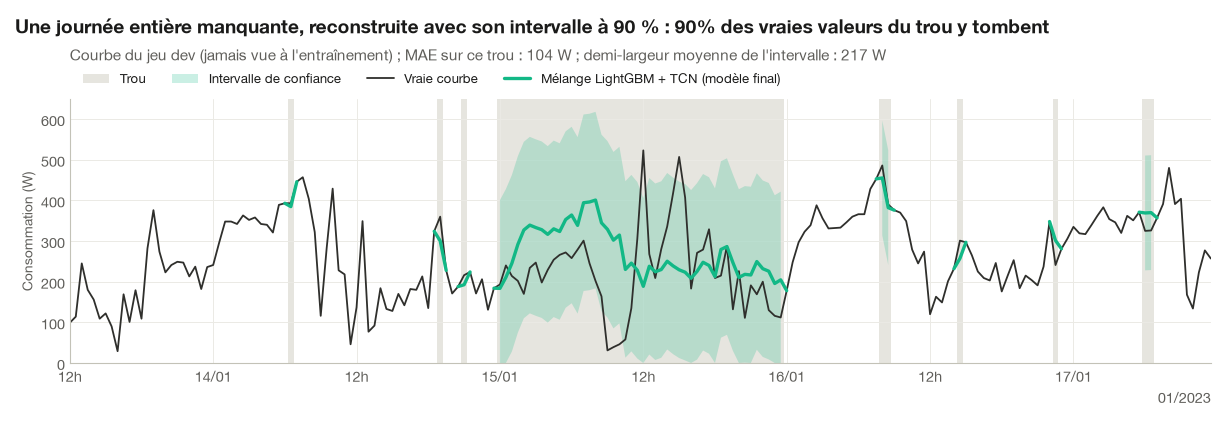

In [6]:
# Image phare : une journée manquante, le mélange et son intervalle à 90 %
cp = comp["dev"]
low90, high90 = intervals(conformal[chosen], cp.blend, cp.classes, sigma=sigma["dev"], alpha=0.1)
shape = (dev.X_holed.shape[1], len(dev.y))  # courbes × temps
full = {}
for name, values in [("pred", cp.blend), ("low", low90), ("high", high90)]:
    full[name] = np.full(shape, np.nan)
    full[name][cp.c, cp.t] = values
y_ct = dev.y.to_numpy().T
runs = hole_runs(dev.mask)
long = runs[
    (runs["length"] == 48) & (runs["start"] >= 48) & (runs["start"] + 48 <= len(dev.y) - 48)
].copy()
long["mae"] = [
    np.abs(full["pred"][c, s : s + n] - y_ct[c, s : s + n]).mean()
    for c, s, n in zip(long["curve"], long["start"], long["length"], strict=True)
]
# Exemple typique : erreur proche de la médiane des journées manquantes, courbe de niveau
# entre le 60e et le 90e centile (lisible)
level = dev.y.mean().to_numpy()[long["curve"]]
lo_lvl, hi_lvl = np.percentile(level, [60, 90])
pool = long[(level > lo_lvl) & (level < hi_lvl)]
ex = pool.loc[(pool["mae"] - pool["mae"].median()).abs().idxmin()]
c, s, n = int(ex["curve"]), int(ex["start"]), int(ex["length"])
col = dev.X_holed.columns[c]
inside = slice(s, s + n)
covered = np.mean(
    (y_ct[c, inside] >= full["low"][c, inside]) & (y_ct[c, inside] <= full["high"][c, inside])
)
half_width = np.mean(full["high"][c, inside] - full["pred"][c, inside])
fig = plot_imputation(
    dev.y[col],
    {"Mélange LightGBM + TCN (modèle final)": full["pred"][c]},
    dev.mask[:, c],
    f"Une journée entière manquante, reconstruite avec son intervalle à 90 % : "
    f"{covered:.0%} des vraies valeurs du trou y tombent",
    interval=(full["low"][c], full["high"][c]),
    window=slice(max(0, s - 72), min(len(dev.y), s + n + 72)),
)
fig.axes[0].set_title(
    f"Courbe du jeu dev (jamais vue à l'entraînement) ; MAE sur ce trou : {ex['mae']:.0f} W ; "
    f"demi-largeur moyenne de l'intervalle : {half_width:.0f} W",
    pad=28,
)
save_fig(fig, "u2_intervalle_long_trou");

**Constat → conséquence (intervalles)**

- **La variante simple, un quantile par classe de longueur de trou, gagne** : c'est la plus étroite des variantes qui couvrent correctement. À 90 %, sa largeur moyenne est de ~290 W (±145 W), contre ~305–310 W pour les variantes normalisées. Sa couverture atteint 89,3 % sur dev et 89,5 % sur real, et chaque classe reste entre 88,8 % et 90,3 %. À 80 %, elle couvre 79,4 % et 79,8 %.
- **Normaliser par la difficulté n'aide pas ici**, alors même que le modèle de difficulté classe correctement les points (corrélation de rang de 0,68 avec l'erreur réelle). Les erreurs ont des queues lourdes, avec des pics de consommation imprévisibles même sur des points jugés « faciles ». Diviser par σ̂ élargit les intervalles des points faciles plus qu'il ne resserre ceux des points difficiles.
- **Les intervalles sont larges** : ±145 W à 90 %, pour une consommation moyenne d'environ 350 W aux points manquants. C'est le reflet honnête de la volatilité des courbes individuelles : un pic de chauffe ou d'électroménager d'une demi-heure n'est pas prévisible.
- → On retient les **intervalles par classe**. À l'échelle d'un client, une valeur reconstruite est une **estimation à ±145 W près 9 fois sur 10**. À l'échelle d'un agrégat, les erreurs se compensent largement (partie B).

## B. Impact sur les agrégats (vision métier)

Pour un gestionnaire de réseau, une erreur qui se compense d'un client à l'autre pèse peu ; un **biais systématique**, lui, fausse les bilans d'énergie et les prévisions de charge. Un modèle entraîné en L1 vise la **médiane** conditionnelle : sur des consommations asymétriques (pics rares mais forts), il a tendance à **sous-estimer en moyenne**.

In [7]:
interp_rows = {}
for split, X in [("dev", dev.X_holed), ("real", real.X_holed)]:
    filled = linear_interpolation(X, None).to_numpy()
    interp_rows[split] = filled[comp[split].t, comp[split].c]

bias = pd.concat(
    {
        (split, name): bias_table(pred, truth[split], comp[split].classes)
        for split in ["dev", "real"]
        for name, pred in [("Interpolation", interp_rows[split]), ("Mélange", comp[split].blend)]
    }
)
display(bias.round(3))


def aggregate(split: str, pred: np.ndarray) -> dict[str, float | np.ndarray]:
    """Courbe agrégée des points manquants (somme sur les courbes à chaque pas) et erreurs."""
    cp, y = comp[split], truth[split]
    ok = ~np.isnan(y)
    T = len(dev.y)
    true_agg, pred_agg = np.zeros(T), np.zeros(T)
    np.add.at(true_agg, cp.t[ok], y[ok])
    np.add.at(pred_agg, cp.t[ok], pred[ok])
    kwh = 0.5 / 1000  # W pendant 30 min → kWh
    return {
        "vraie": true_agg,
        "reconstruite": pred_agg,
        "énergie manquante (kWh)": true_agg.sum() * kwh,
        "erreur signée (kWh)": (pred_agg - true_agg).sum() * kwh,
        "erreur signée (%)": (pred_agg - true_agg).sum() / true_agg.sum(),
        "MAE de la courbe agrégée (W)": np.abs(pred_agg - true_agg).mean(),
        "MAE agrégée (%)": np.abs(pred_agg - true_agg).sum() / true_agg.sum(),
    }


agg = {
    (split, name): aggregate(split, pred)
    for split in ["dev", "real"]
    for name, pred in [("Interpolation", interp_rows[split]), ("Mélange", comp[split].blend)]
}
display(
    pd.DataFrame(
        {k: {m: v for m, v in d.items() if not isinstance(v, np.ndarray)} for k, d in agg.items()}
    ).T.round(3)
)

biais (W)  biais (%)  MAE (W)
                   classe                               
dev  Interpolation 1           0.166      0.000   62.195
                   2           0.800      0.002   71.877
                   3-6         0.564      0.002   77.430
                   7-48        1.151      0.003  143.360
                   >48       -23.462     -0.059  154.056
                   toutes     -1.555     -0.005  104.287
     Mélange       1          -6.177     -0.018   50.895
                   2          -8.846     -0.026   58.365
                   3-6       -11.399     -0.033   63.802
                   7-48      -18.571     -0.055   82.152
                   >48       -23.113     -0.059   90.824
                   toutes    -13.159     -0.038   68.353
real Interpolation 1           0.570      0.002   62.095
                   2           0.090      0.000   71.188
                   3-6        -4.582     -0.013   78.669
                   7-48       -8.415     -0.024  139.821
                   >48        24.169      0.070  145.381
                   toutes     -1.062     -0.003  101.951
     Mélange       1          -6.062     -0.017   50.538
                   2          -6.609     -0.019   57.559
                   3-6       -13.657     -0.039   65.836
                   7-48      -17.447     -0.049   81.473
                   >48       -17.913     -0.052   79.205
                   toutes    -11.898     -0.034   66.816

énergie manquante (kWh)  erreur signée (kWh)  \
dev  Interpolation               44,415.354             -200.321   
     Mélange                     44,415.354           -1,694.937   
real Interpolation               22,810.174              -68.421   
     Mélange                     22,810.174             -766.520   

                    erreur signée (%)  MAE de la courbe agrégée (W)  \
dev  Interpolation             -0.005                     3,247.754   
     Mélange                   -0.038                     3,458.960   
real Interpolation             -0.003                     2,445.797   
     Mélange                   -0.034                     1,762.100   

                    MAE agrégée (%)  
dev  Interpolation            0.039  
     Mélange                  0.041  
real Interpolation            0.057  
     Mélange                  0.041

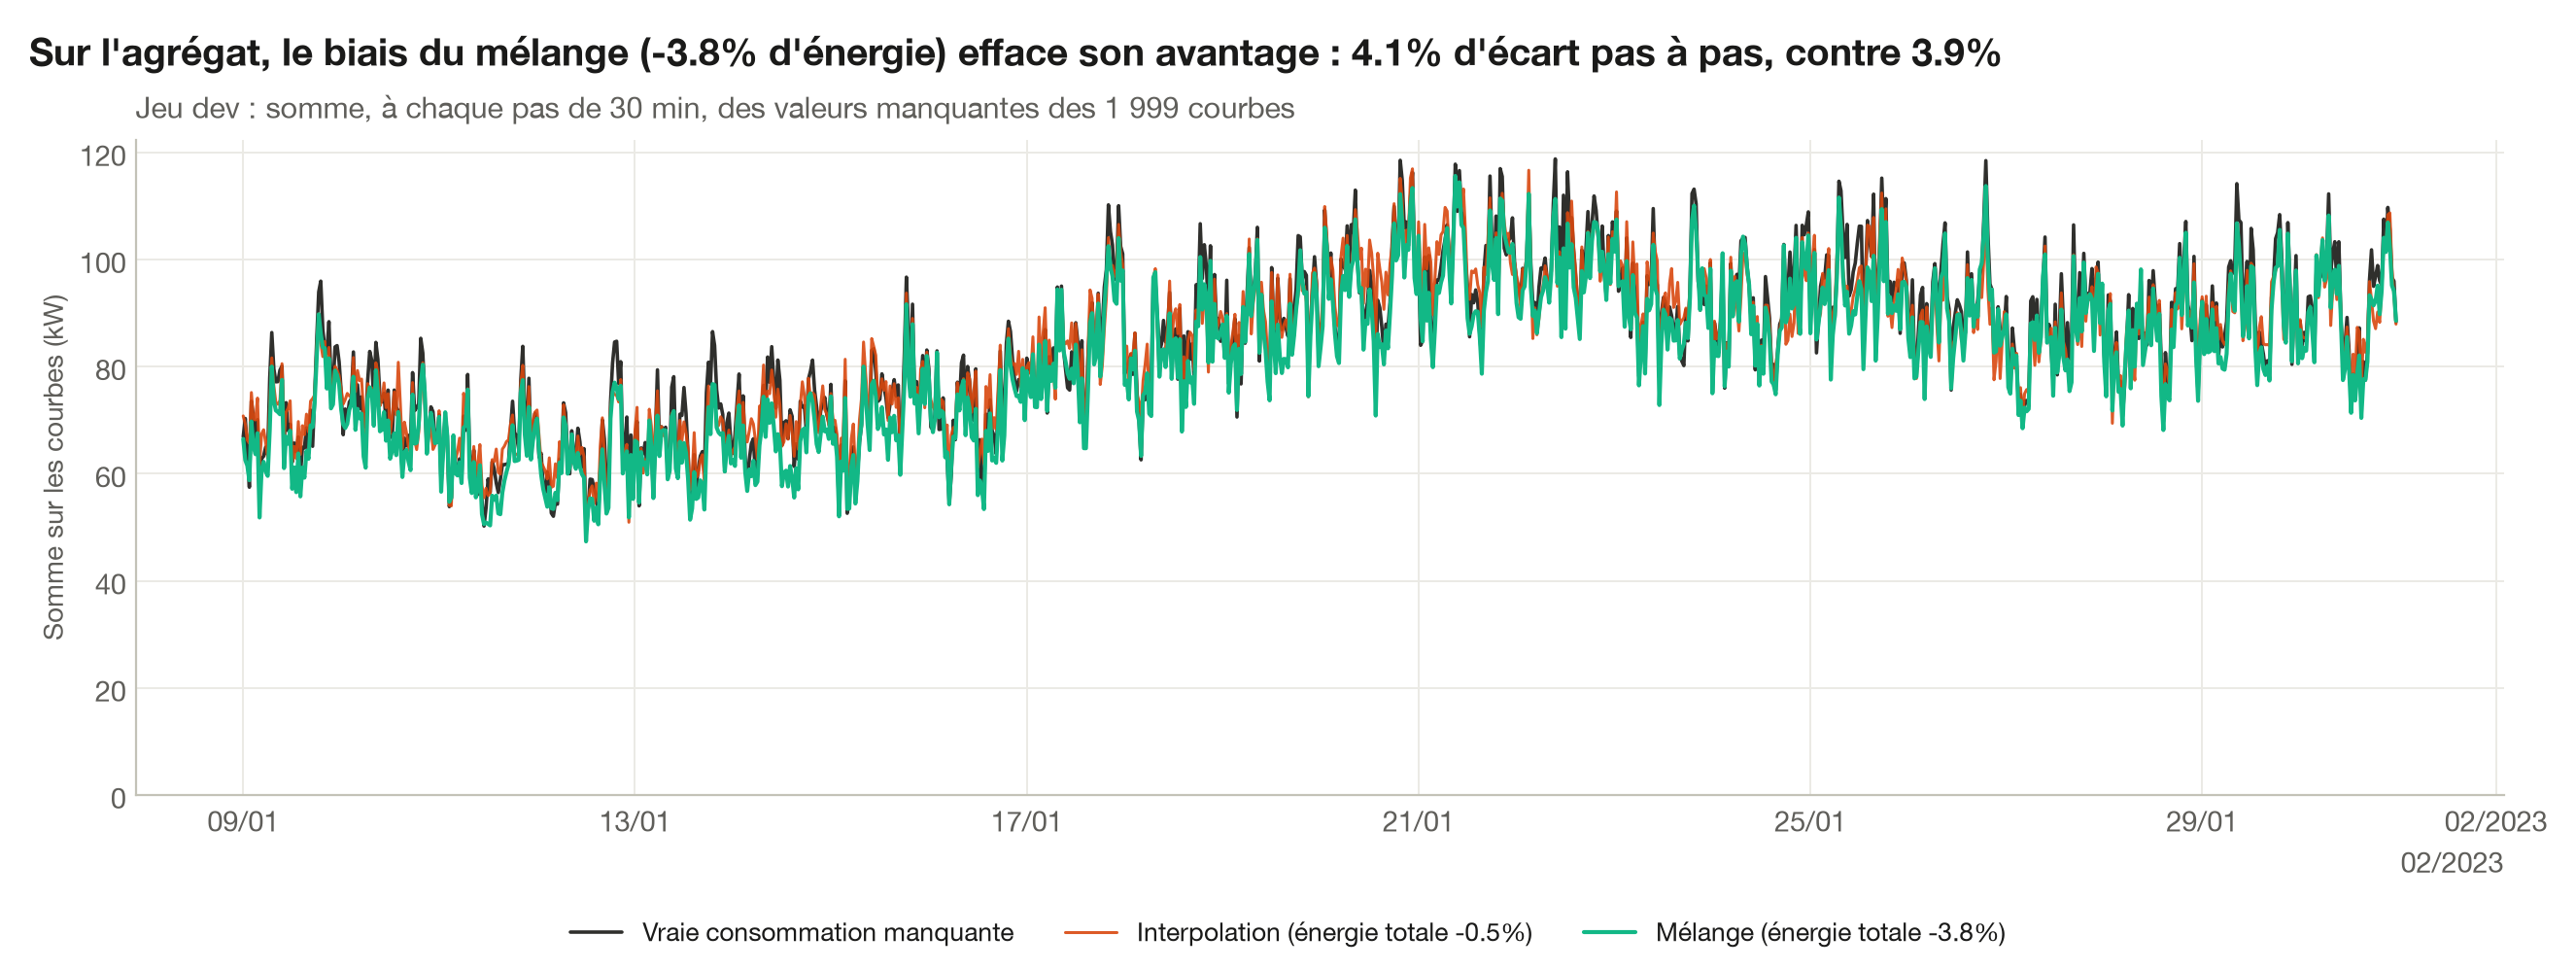

In [8]:
idx = dev.y.index[:-1]  # le dernier pas (31/01 00:00) est isolé : on l'écarte du tracé
a_int, a_mix = agg[("dev", "Interpolation")], agg[("dev", "Mélange")]
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(
    idx, a_int["vraie"][:-1] / 1000, color=P["true"], lw=1.3, label="Vraie consommation manquante"
)
ax.plot(
    idx,
    a_int["reconstruite"][:-1] / 1000,
    color=method_color("Interpolation"),
    lw=1.1,
    alpha=0.9,
    label=f"Interpolation (énergie totale {a_int['erreur signée (%)']:+.1%})",
)
ax.plot(
    idx,
    a_mix["reconstruite"][:-1] / 1000,
    color=method_color("Mélange"),
    lw=1.5,
    label=f"Mélange (énergie totale {a_mix['erreur signée (%)']:+.1%})",
)
ax.set_ylabel("Somme sur les courbes (kW)")
ax.set_ylim(bottom=0)
ax.set_title("Jeu dev : somme, à chaque pas de 30 min, des valeurs manquantes des 1 999 courbes")
fig.legend(loc="outside lower center", ncol=3)
gap_mix, gap_int = a_mix["MAE agrégée (%)"], a_int["MAE agrégée (%)"]
if gap_mix < gap_int:
    title = (
        f"Sur l'agrégat aussi, le mélange suit mieux la charge manquante : {gap_mix:.1%} "
        f"d'écart pas à pas, contre {gap_int:.1%} pour l'interpolation"
    )
else:
    title = (
        f"Sur l'agrégat, le biais du mélange ({a_mix['erreur signée (%)']:+.1%} d'énergie) "
        f"efface son avantage : {gap_mix:.1%} d'écart pas à pas, contre {gap_int:.1%}"
    )
set_conclusion(fig, title)
save_fig(fig, "u3_courbe_agregee");

In [9]:
# Correction du biais : décalage moyen appris sur la calibration, appliqué avec un poids λ
shift = float(np.nanmean(comp["calibration"].blend - truth["calibration"]))
print(f"Décalage moyen du mélange sur la calibration : {shift:+.2f} W")
trade = {}
for split in ["dev", "real"]:
    y, ok_ = truth[split], ~np.isnan(truth[split])
    for lam in [0.0, 0.25, 0.5, 0.75, 1.0]:
        p = np.clip(comp[split].blend - lam * shift, 0, None)
        trade[(split, lam)] = {
            "MAE (W)": np.abs(p - y)[ok_].mean(),
            "biais (W)": (p - y)[ok_].mean(),
            "erreur sur l'énergie (%)": (p - y)[ok_].sum() / y[ok_].sum(),
        }
display(pd.DataFrame(trade).T.rename_axis(["jeu", "λ"]).round(3))

Décalage moyen du mélange sur la calibration : -12.21 W


MAE (W)  biais (W)  erreur sur l'énergie (%)
jeu  λ                                                  
dev  0.000   68.353    -13.159                    -0.038
     0.250   68.822    -10.106                    -0.029
     0.500   69.550     -7.054                    -0.020
     0.750   70.470     -4.002                    -0.012
     1.000   71.548     -0.949                    -0.003
real 0.000   66.816    -11.898                    -0.034
     0.250   67.279     -8.845                    -0.025
     0.500   68.015     -5.793                    -0.016
     0.750   68.953     -2.741                    -0.008
     1.000   70.052      0.312                     0.001

**Constat → conséquence (biais et agrégats)**

- **Le mélange sous-estime systématiquement** :
  - −13 W en moyenne sur dev, soit **−3,8 % de l'énergie manquante** ; −3,4 % sur real ;
  - le biais croît avec la longueur du trou : −1,8 % sur les trous d'1 point, environ −6 % au-delà de 48 points.
  
  C'est l'effet attendu de l'objectif L1 : le modèle vise la **médiane** conditionnelle, et les consommations ont une distribution asymétrique (des pics rares mais forts tirent la moyenne vers le haut). **L'interpolation, elle, n'a presque aucun biais** (−0,5 %) : moyenne de deux valeurs observées, elle est en moyenne juste, même quand elle se trompe beaucoup point par point.
- **Sur l'agrégat, l'avantage du mélange disparaît.** Sommées sur 2 000 courbes, les erreurs individuelles se compensent ; seul le biais reste. Résultat, en écart moyen pas à pas sur la courbe agrégée :
  - **dev** : 4,1 % pour le mélange, contre 3,9 % pour l'interpolation ;
  - **real** : 4,1 % contre 5,7 % (l'interpolation y paie ses erreurs sur les longs trous).
  
  Une MAE individuelle 35 % plus faible ne garantit pas un meilleur bilan : **la MAE et le bilan sont deux objectifs différents.**
- **Corriger le biais a un prix en MAE.** On soustrait λ fois le décalage moyen mesuré sur la calibration (−12,2 W) :

  | λ | MAE dev | biais dev (énergie) | MAE real | biais real (énergie) |
  |---|---|---|---|---|
  | 0 | 68,4 W | −3,8 % | 66,8 W | −3,4 % |
  | 0,5 | 69,6 W | −2,0 % | 68,0 W | −1,6 % |
  | 1 | 71,5 W | −0,3 % | 70,1 W | +0,1 % |

- → **Deux usages, deux réglages, décidés ici avant le holdout.**
  - Pour le challenge (jugé en MAE) et la reconstruction d'une courbe individuelle : **pas de correction**.
  - Pour un **bilan d'énergie ou un agrégat** : appliquer le décalage complet (λ = 1), qui annule le biais pour environ 3 W de MAE en plus.
  - Une piste plus fine pour le second usage serait un objectif qui vise la moyenne (L2, ou L1 suivi d'une recalibration par classe).

## C. Score final sur le holdout (première et unique utilisation)

Toutes les décisions sont prises. On évalue maintenant, **en une seule fois**, les six méthodes sur les 1 999 courbes du holdout — jamais utilisées pour quoi que ce soit depuis leur création à l'étape 3 (seul le benchmark sans paramètre y avait été évalué, comme référence). Rien n'est réglé après cette cellule.

In [10]:
holdout = load_split("holdout")
methods = {
    "Interpolation linéaire": linear_interpolation,
    "KNN naïf (médiane de 5)": knn_median,
    "KNN ancré": anchored_knn,
    "LightGBM": make_method(booster, gbm_cfg),
    "Réseau TCN": make_network_method(tcn),
    "Mélange": make_blend_method(booster, gbm_cfg, tcn, W),
}
registry_names = {
    "LightGBM": "LightGBM résidu, 63 feuilles",
    "Mélange": f"Mélange (w = {W:.2f}, TCN)",
}
final = {
    "holdout": {
        k: evaluate(m, holdout, name=registry_names.get(k, k), allow_holdout=True)
        for k, m in methods.items()
    },
    # dev et real : déjà au registre (notebooks 02 à 05) ; réévalués ici sans réenregistrement
    "dev": {k: evaluate(m, dev, register=False) for k, m in methods.items()},
    "real": {k: evaluate(m, real, register=False) for k, m in methods.items()},
}
with mlflow.start_run(run_name="Score final — mélange"):
    mlflow.log_params({"w_lightgbm": W, "intervalles": chosen})
    for split in final:
        log_evaluation(final[split]["Mélange"])

In [11]:
# Couverture des intervalles sur le holdout
comp_h = predict_components(holdout.X_holed, holdout.reservoir, booster, gbm_cfg, tcn, W)
y_h = holdout.y.to_numpy()[comp_h.t, comp_h.c]
sigma_h = difficulty(diff_model, comp_h.feats)
cov_h = pd.concat(
    {
        f"{1 - a:.0%}": coverage_table(
            y_h,
            *intervals(conformal[chosen], comp_h.blend, comp_h.classes, sigma=sigma_h, alpha=a),
            comp_h.classes,
        )
        for a in ALPHAS
    },
    axis=1,
)
display(cov_h.round(3))
display(bias_table(comp_h.blend, y_h, comp_h.classes).round(3))

80%                    90%            
       couverture largeur (W) couverture largeur (W)
classe                                              
1           0.800     118.136      0.898     216.047
2           0.799     132.041      0.896     244.031
3-6         0.795     148.651      0.887     258.809
7-48        0.815     210.054      0.906     354.429
>48         0.813     211.443      0.901     356.694
toutes      0.807     165.678      0.901     288.685

,biais (W),biais (%),MAE (W)
classe,,,
1,-6.016,-0.018,48.327
2,-8.545,-0.026,55.425
3-6,-8.410,-0.026,63.258
7-48,-20.719,-0.063,77.719
>48,-16.500,-0.054,80.648
toutes,-13.178,-0.040,64.350


In [12]:
def class_table(res: dict) -> pd.DataFrame:
    """MAE par classe (+ globale) de chaque méthode."""
    return pd.DataFrame(
        {k: [*r.by_class["mae"].to_numpy(), r.mae] for k, r in res.items()},
        index=[*LENGTH_LABELS, "toutes"],
    ).T


final_table = pd.concat({s: class_table(final[s]) for s in ["dev", "holdout", "real"]})
display(final_table.round(1))
gains = pd.concat(
    {
        (s, k): paired_difference(final[s][k], final[s]["Interpolation linéaire"]).loc["toutes"]
        for s in ["dev", "holdout", "real"]
        for k in methods
        if k != "Interpolation linéaire"
    },
    axis=1,
).T.rename_axis(["jeu", "méthode"])
gains["en %"] = gains["différence"] / pd.Series(
    {(s, k): final[s]["Interpolation linéaire"].mae for s, k in gains.index}
)
display(gains.round(2))

1       2     3-6    7-48     >48  \
dev     Interpolation linéaire   62.200  71.900  77.400 143.400 154.100   
        KNN naïf (médiane de 5) 104.600 103.700 107.000 106.600 113.500   
        KNN ancré                60.900  70.100  75.300  99.100 108.900   
        LightGBM                 55.800  63.000  68.000  85.700  95.700   
        Réseau TCN               50.900  58.600  64.000  82.500  91.200   
        Mélange                  50.900  58.400  63.800  82.200  90.800   
holdout Interpolation linéaire   58.600  67.500  76.800 140.100 150.800   
        KNN naïf (médiane de 5) 100.100 101.700 103.300 103.400 100.500   
        KNN ancré                57.700  66.400  74.600  94.900  94.600   
        LightGBM                 52.900  59.400  67.700  81.300  83.800   
        Réseau TCN               48.400  55.600  63.500  78.000  81.000   
        Mélange                  48.300  55.400  63.300  77.700  80.600   
real    Interpolation linéaire   62.100  71.200  78.700 139.800 145.400   
        KNN naïf (médiane de 5) 103.200 101.700 107.900 105.400  97.600   
        KNN ancré                60.600  69.300  76.400  98.700  93.700   
        LightGBM                 55.700  62.500  69.700  85.300  83.200   
        Réseau TCN               50.500  57.700  66.300  81.800  79.600   
        Mélange                  50.500  57.600  65.800  81.500  79.200   

                                 toutes  
dev     Interpolation linéaire  104.300  
        KNN naïf (médiane de 5) 106.100  
        KNN ancré                82.100  
        LightGBM                 72.700  
        Réseau TCN               68.600  
        Mélange                  68.400  
holdout Interpolation linéaire  100.800  
        KNN naïf (médiane de 5) 101.800  
        KNN ancré                77.500  
        LightGBM                 68.300  
        Réseau TCN               64.500  
        Mélange                  64.300  
real    Interpolation linéaire  102.000  
        KNN naïf (médiane de 5) 103.400  
        KNN ancré                80.400  
        LightGBM                 71.300  
        Réseau TCN               67.000  
        Mélange                  66.800

différence  IC bas  IC haut   en %
jeu     méthode                                                    
dev     KNN naïf (médiane de 5)       1.830  -0.770    4.410  0.020
        KNN ancré                   -22.170 -24.560  -19.530 -0.210
        LightGBM                    -31.620 -34.520  -28.520 -0.300
        Réseau TCN                  -35.720 -38.740  -32.550 -0.340
        Mélange                     -35.930 -38.990  -32.760 -0.340
holdout KNN naïf (médiane de 5)       0.980  -2.020    3.870  0.010
        KNN ancré                   -23.330 -26.380  -20.780 -0.230
        LightGBM                    -32.510 -35.840  -29.570 -0.320
        Réseau TCN                  -36.270 -39.700  -33.340 -0.360
        Mélange                     -36.450 -39.890  -33.490 -0.360
real    KNN naïf (médiane de 5)       1.500  -2.710    5.440  0.010
        KNN ancré                   -21.580 -25.940  -17.950 -0.210
        LightGBM                    -30.690 -35.180  -26.870 -0.300
        Réseau TCN                  -34.940 -39.770  -30.770 -0.340
        Mélange                     -35.140 -39.940  -31.000 -0.340

/Users/thibaudperes/projets/enedis-imputation/src/enedis_imputation/viz.py:325: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Neue.
  fig.savefig(path)
/Users/thibaudperes/projets/enedis-imputation/.venv/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Neue.
  func(*args, **kwargs)


/Users/thibaudperes/projets/enedis-imputation/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica Neue.
  fig.canvas.print_figure(bytes_io, **kw)


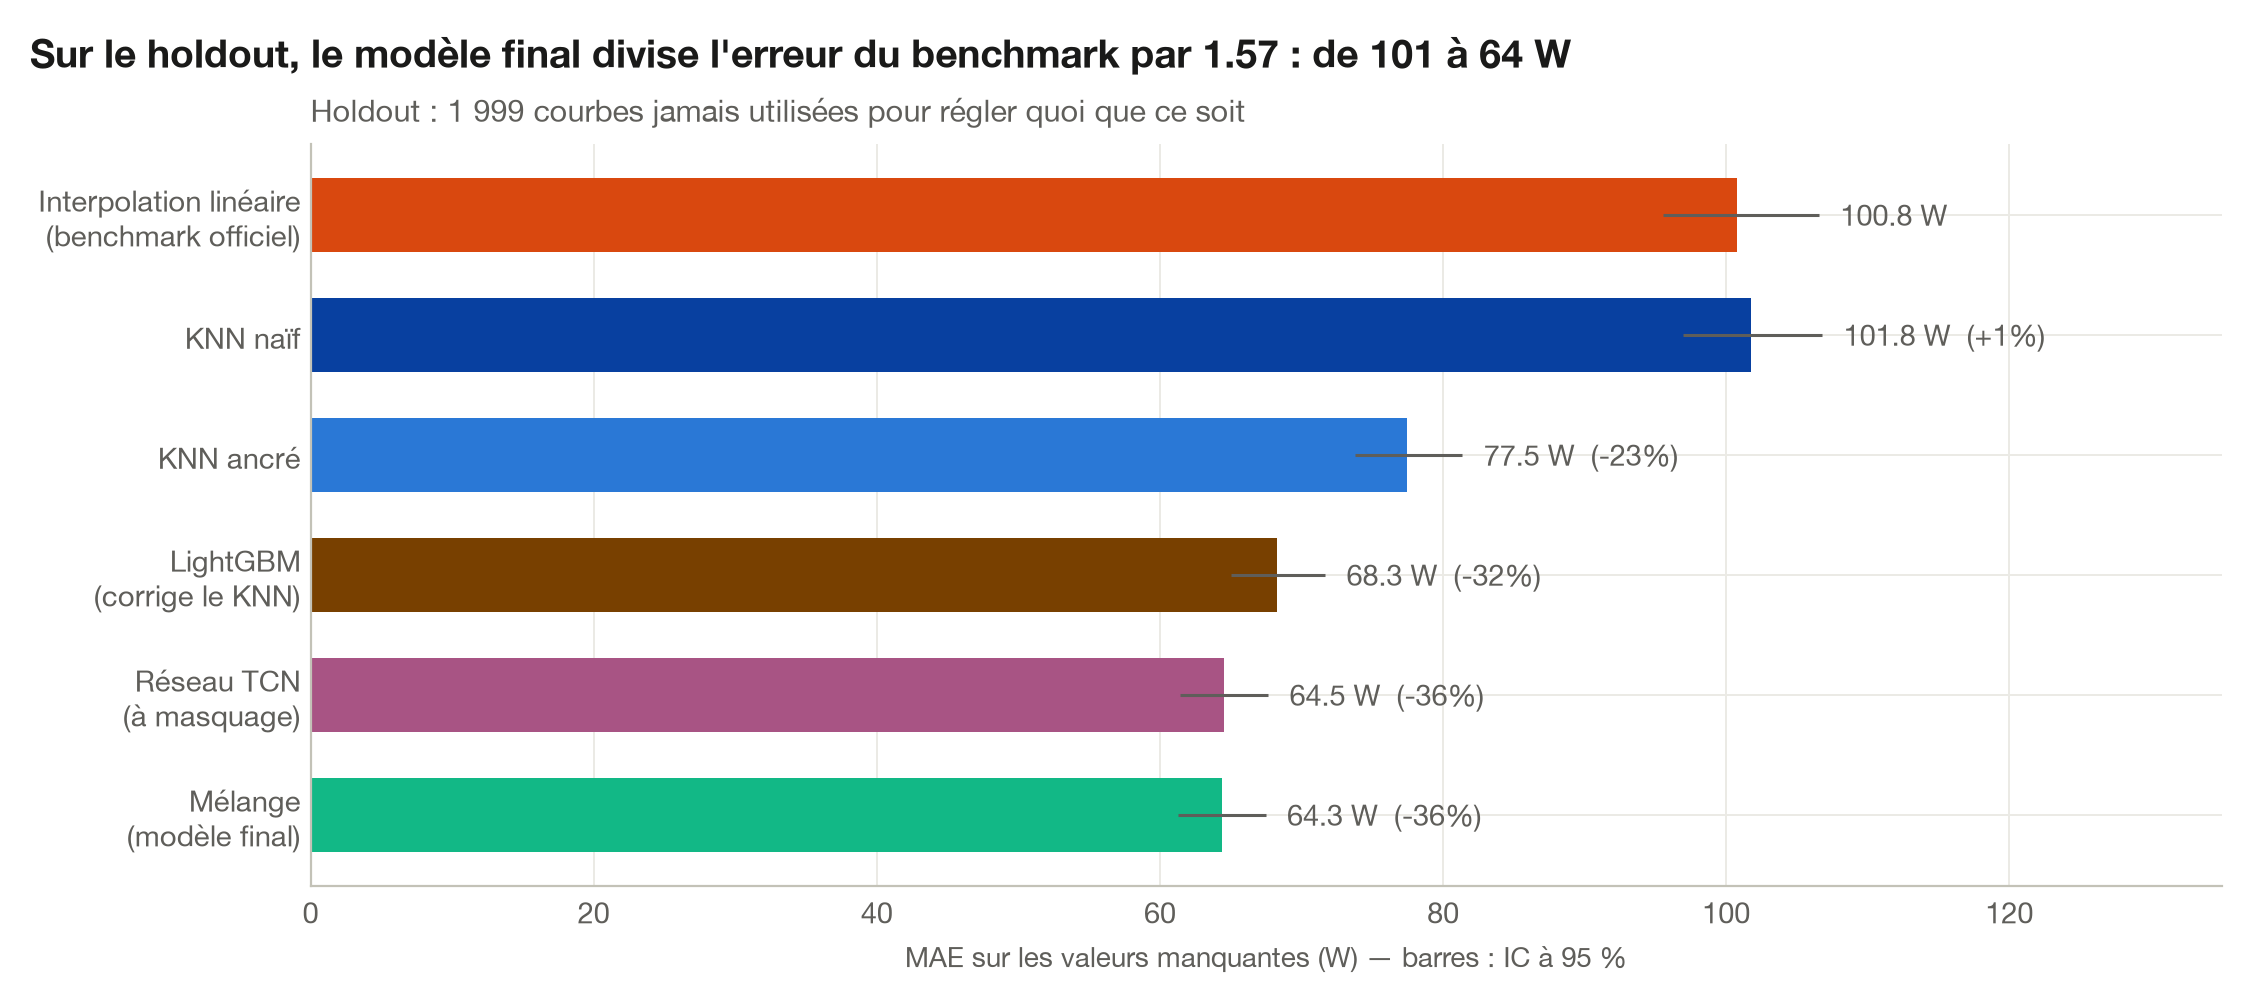

In [13]:
order = list(methods)
r_h = final["holdout"]
bench = r_h["Interpolation linéaire"].mae
fig, ax = plt.subplots(figsize=(11, 4.8))
y_pos = np.arange(len(order))[::-1]
for yi, name in zip(y_pos, order, strict=True):
    r = r_h[name]
    ax.barh(yi, r.mae, height=0.62, color=method_color(name))
    ax.errorbar(
        r.mae,
        yi,
        xerr=[[r.mae - r.ci[0]], [r.ci[1] - r.mae]],
        fmt="none",
        ecolor=P["ink_secondary"],
        elinewidth=1.1,
    )
    gain = "" if name == "Interpolation linéaire" else f"  ({r.mae / bench - 1:+.0%})"
    ax.text(r.ci[1] + 1.5, yi, f"{r.mae:.1f} W{gain}", va="center", color=P["ink_secondary"])
ax.set_yticks(
    y_pos,
    [
        "Interpolation linéaire\n(benchmark officiel)",
        "KNN naïf",
        "KNN ancré",
        "LightGBM\n(corrige le KNN)",
        "Réseau TCN\n(à masquage)",
        "Mélange\n(modèle final)",
    ],
)
ax.set_xlim(0, 135)
ax.set_xlabel("MAE sur les valeurs manquantes (W) — barres : IC à 95 %")
ax.set_title("Holdout : 1 999 courbes jamais utilisées pour régler quoi que ce soit")
final_mae = r_h["Mélange"].mae
set_conclusion(
    fig,
    f"Sur le holdout, le modèle final divise l'erreur du benchmark par {bench / final_mae:.2f} : "
    f"de {bench:.0f} à {final_mae:.0f} W",
)
save_fig(fig, "u4_score_final");

**Constat → conséquence (holdout)**

| MAE (W) | 1 pt | 2 pts | 3–6 pts | 7–48 pts | > 48 pts | Toutes | Gain apparié vs benchmark |
|---|---|---|---|---|---|---|---|
| Interpolation (benchmark) | 58,6 | 67,5 | 76,8 | 140,1 | 150,8 | 100,8 | — |
| KNN naïf | 100,1 | 101,7 | 103,3 | 103,4 | 100,5 | 101,8 | +1,0 W [−2,0 ; +3,9] |
| KNN ancré | 57,7 | 66,4 | 74,6 | 94,9 | 94,6 | 77,5 | −23,3 W (−23 %) |
| LightGBM | 52,9 | 59,4 | 67,7 | 81,3 | 83,8 | 68,3 | −32,5 W (−32 %) |
| TCN | 48,4 | 55,6 | 63,5 | 78,0 | 81,0 | 64,5 | −36,3 W (−36 %) |
| **Mélange** | **48,3** | **55,4** | **63,3** | **77,7** | **80,6** | **64,3** | **−36,5 W [−39,9 ; −33,5] (−36 %)** |

- **Le holdout confirme tout, dans le même ordre.** Chaque étape apporte un gain significatif, et les gains relatifs sont les mêmes que sur dev (−34 %) et real (−34 %). Les valeurs absolues sont un peu plus basses sur le holdout (benchmark à 100,8 W contre 104,3 W sur dev) : ses courbes sont légèrement plus faciles, ce qui touche toutes les méthodes de la même façon.
- **Les intervalles tiennent sur le holdout** : 80,7 % de couverture à 80 % (80 % visés) et **90,1 % à 90 %**, chaque classe entre 88,7 % et 90,6 %, pour des largeurs moyennes de 166 W et 289 W.
- **Le biais aussi** : −4,0 % de l'énergie manquante, comme sur dev et real.
- → Aucun sur-ajustement à dev : malgré une centaine d'évaluations sur dev au fil du projet, le score honnête du holdout est cohérent avec lui. Le protocole a tenu.

## D. Soumission

Pour la soumission, le réservoir de voisines devient **toutes les courbes complètes du train et du test** (~57 000, aux mêmes dates). Les modèles ont été entraînés avec ~16 000 voisines : on vérifie d'abord sur dev que le mélange réagit sainement à la taille du réservoir.

In [14]:
# Stabilité : le mélange avec 8 000 voisines contre 16 001 (sur dev)
order_res = np.random.default_rng(42).permutation(dev.reservoir.columns.to_numpy())
stab = {}
for n in [8000, len(order_res)]:
    sp = Split("dev", dev.X_holed, dev.y, dev.reservoir[order_res[:n]])
    stab[n] = {k: evaluate(methods[k], sp, register=False) for k in ["KNN ancré", "Mélange"]}
display(
    pd.DataFrame({n: {k: r.mae for k, r in res.items()} for n, res in stab.items()})
    .T.rename_axis("taille du réservoir")
    .round(2)
)
d = paired_difference(stab[len(order_res)]["Mélange"], stab[8000]["Mélange"]).loc["toutes"]
ci = f"[{d['IC bas']:+.2f}, {d['IC haut']:+.2f}]"
print(f"Mélange, 16 001 − 8 000 voisines : {d['différence']:+.2f} W {ci}")

,KNN ancré,Mélange
taille du réservoir,,
8000,83.080,68.840
16001,82.110,68.350


Mélange, 16 001 − 8 000 voisines : -0.49 W [-0.66, -0.34]


In [15]:
# Réservoir de la soumission : courbes complètes (sans NaN) du train et du test
X_full, _, _ = load_train()
T_full, T_holed = load_test()
reservoir_final = pd.concat(
    [X_full.loc[:, X_full.notna().all()], T_full.loc[:, T_full.notna().all()]], axis=1
)
assert reservoir_final.columns.is_unique
assert not reservoir_final.columns.intersection(
    T_holed.columns
).size  # aucune cible dans le réservoir
print(f"Réservoir de la soumission : {reservoir_final.shape[1]:,} courbes".replace(",", " "))

filled = methods["Mélange"](T_holed, reservoir_final)
sample = read_sample()
submission = to_submission(filled, sample)
check_submission(submission, sample, T_holed)
path = write_submission(submission)
print(f"Soumission écrite : {path}")
n_filled = int(T_holed.isna().to_numpy().sum())
print(
    f"{n_filled:,} valeurs remplies ; aucune valeur observée modifiée ; ".replace(",", " ")
    + "aucun NaN ; toutes ≥ 0"
)

Réservoir de la soumission : 57 135 courbes


Soumission écrite : /Users/thibaudperes/projets/enedis-imputation/data/processed/submission.csv
128 763 valeurs remplies ; aucune valeur observée modifiée ; aucun NaN ; toutes ≥ 0


**Constat → conséquence (soumission)**

- **Changer la taille du réservoir est sans risque.** Sur dev, le mélange **s'améliore** quand le réservoir grandit : 68,84 W avec 8 000 voisines, 68,35 W avec 16 001, soit −0,49 W [−0,66 ; −0,34]. Son gain sur le KNN ancré reste stable (−14,2 puis −13,8 W). Le passage à 57 135 voisines va dans le même sens.
- **Soumission** : `data/processed/submission.csv`.
  - 1 057 lignes × 1 000 colonnes, même en-tête, même index et même ordre que `sample_submission.csv` ;
  - 128 763 valeurs remplies, aucune valeur observée modifiée, aucun NaN, toutes ≥ 0 ;
  - vérifié par `check_submission` et par `tests/test_submission.py`.
- **Score attendu** : de l'ordre de 64–68 W (holdout, real et dev encadrent cette valeur), plutôt vers le bas grâce au réservoir plus grand, contre ~102 W pour le benchmark. C'est une estimation : le score public de la plateforme est calculé sur une partie du test.

## Synthèse finale

1. **Du benchmark au modèle final, l'erreur baisse de 36 %** sur le holdout, jamais utilisé avant ce notebook : de 100,8 à 64,3 W (gain apparié −36,5 W [−39,9 ; −33,5]).
2. **Chaque idée compte** :
   - KNN ancré (−23 %) : ancrer sur les bords, choisir les voisines sur leur forme, les remettre au niveau ;
   - LightGBM (−32 %) : exploiter la mémoire de la courbe à la même heure ;
   - réseau à masquage (−36 %) : voir toute la courbe d'un coup ;
   - le mélange final n'ajoute que 0,2 W, car les deux modèles se trompent aux mêmes endroits.
3. **On sait à quel point se fier à chaque valeur** : des intervalles conformes à 90 % couvrent 90,1 % des vraies valeurs sur le holdout, dans toutes les classes de trous, avec une largeur moyenne de ±145 W.
4. **Limite métier, assumée et mesurée** : le modèle sous-estime l'énergie manquante de ~4 %, effet de l'objectif L1, et sur un agrégat l'interpolation non biaisée fait jeu égal. Pour un bilan d'énergie, un décalage appris sur la calibration annule le biais, pour ~3 W de MAE en plus.
5. **Le protocole a tenu** : faux trous greffés validés contre de vrais trous, anti-fuite testée, holdout utilisé une seule fois, toutes les décisions prises sur dev ou sur la calibration. Les scores de dev, real et holdout racontent la même histoire.

**Déposer la soumission** (plateforme Challenge Data ENS) :
1. Se connecter sur https://challengedata.ens.fr avec le compte inscrit au challenge.
2. Ouvrir la page du challenge n°160 (Enedis, « Comment remplir les valeurs manquantes de consommation électrique des clients ? »).
3. Dans la partie de dépôt des soumissions de cette page, téléverser `data/processed/submission.csv`. Le score public s'affiche une fois le fichier évalué. Le nombre de soumissions est limité : vérifier la limite affichée avant de déposer.